# 02. Demand Elasticity Modeling & Shopee Simulator Validation
### Memodelkan Kurva Permintaan (Price Elasticity) & Lingkungan Simulasi MDP

- Menguji model elastisitas harga iso-elastis: $Q(p) = Q_{base} (p / p_{base})^{\epsilon}$
- Memasukkan faktor dorongan promosi Shopee (Payday & Double Date Campaign).
- Memverifikasi kalkulasi biaya holding dan penalti stockout.

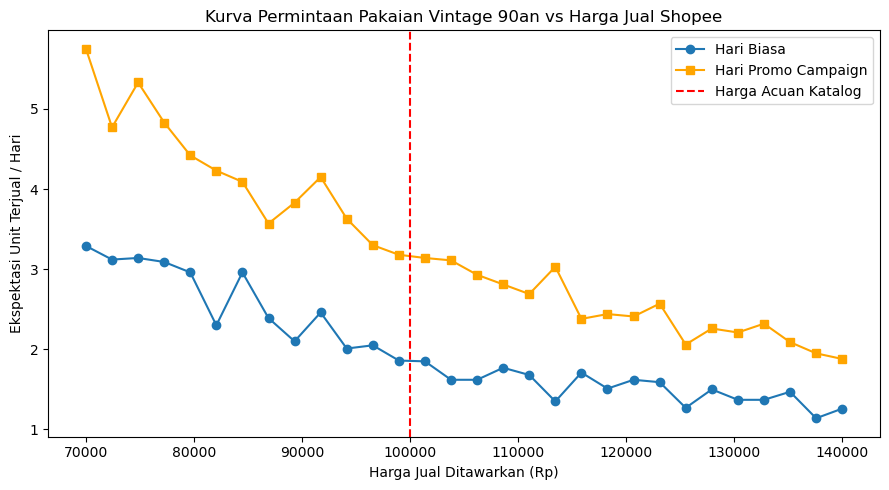

In [1]:
import sys
sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from src.environment.demand_model import ShopeeDemandSimulator
from src.environment.shopee_pricing_env import ShopeeDynamicPricingEnv

# Uji simulasi permintaan pada variasi harga
base_price = 100000
sim = ShopeeDemandSimulator(base_daily_demand=2.0, base_price=base_price, price_elasticity=-1.5)
prices = np.linspace(70000, 140000, 30)
demands_normal = [np.mean([sim.sample_demand(p, is_campaign_day=False) for _ in range(100)]) for p in prices]
demands_campaign = [np.mean([sim.sample_demand(p, is_campaign_day=True) for _ in range(100)]) for p in prices]

plt.figure(figsize=(9, 5))
plt.plot(prices, demands_normal, label="Hari Biasa", marker="o")
plt.plot(prices, demands_campaign, label="Hari Promo Campaign", marker="s", color="orange")
plt.axvline(base_price, color="red", linestyle="--", label="Harga Acuan Katalog")
plt.title("Kurva Permintaan Pakaian Vintage 90an vs Harga Jual Shopee")
plt.xlabel("Harga Jual Ditawarkan (Rp)")
plt.ylabel("Ekspektasi Unit Terjual / Hari")
plt.legend()
plt.tight_layout()
plt.show()